# Bài 15 · Nâng cao: tinh chỉnh hiệu quả (LoRA) và tối ưu suy luận

**Thời lượng gợi ý:** 270 phút · **Cần:** Bài 8, Bài 10, Bài 13 · **GPU ≥ 4 GB** cho mục 3 (mục 1, 2, 4 chạy được trên CPU) · **Cần Internet** lần đầu

## Mục tiêu

1. Tính được **bộ nhớ** cần cho suy luận và cho tinh chỉnh toàn bộ; hiểu vì sao mô hình càng lớn càng khó tinh chỉnh trên máy cá nhân.
2. Hiểu **LoRA** (Low-Rank Adaptation) và **tự cài** nó bằng PyTorch: tham số, khởi tạo, hợp nhất (merge).
3. Dùng thư viện **`peft`** để tinh chỉnh một **LLM nhỏ** (Qwen2.5-0.5B-Instruct) cho phân loại cảm xúc trên dữ liệu thật, rồi so với *zero-shot*, PhoBERT tinh chỉnh toàn bộ và TF-IDF.
4. **Lượng tử hóa** mô hình để suy luận nhẹ và nhanh hơn, và **đo cái giá** — đặc biệt trên lớp hiếm.
5. Đưa ra **quyết định kỹ thuật**: khi nào dùng TF-IDF, PhoBERT, LoRA, hay API LLM.

> Bài này là phần "nâng cao": ghép những gì đã học (Transformer ở Bài 8, tinh chỉnh ở Bài 10, LLM ở Bài 13) để trả lời câu hỏi *thực tế nhất*: **với nguồn lực có hạn, tôi nên làm gì?**

In [1]:
import sys, pathlib

ROOT = pathlib.Path.cwd()
if ROOT.name == "notebooks":
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT))

import warnings
warnings.filterwarnings("ignore")

import os
os.environ.setdefault("HF_HUB_DISABLE_PROGRESS_BARS", "1")
os.environ.setdefault("HF_HUB_DISABLE_SYMLINKS_WARNING", "1")

import io, math, time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import torch
import torch.nn as nn
import torch.nn.functional as F
import transformers
transformers.logging.set_verbosity_error()
from transformers import AutoTokenizer, AutoModelForCausalLM, AutoModelForSequenceClassification, get_linear_schedule_with_warmup

try:
    import peft
    from peft import LoraConfig, PeftModel, get_peft_model
except ImportError as e:
    raise ImportError("Bài này cần thư viện `peft`: pip install -r requirements-transformers.txt") from e

from datasets import load_dataset
from sklearn.metrics import accuracy_score, f1_score, classification_report, precision_recall_fscore_support

from nlpvi import load_hard, set_seed, segment

plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False})
SEED = 42
set_seed(SEED)
device = "cuda" if torch.cuda.is_available() else "cpu"
vram = torch.cuda.get_device_properties(0).total_memory / 1e9 if device == "cuda" else 0
print(f"Thiết bị: {device}" + (f" · VRAM {vram:.1f} GB" if device == "cuda" else "") + f" | peft {peft.__version__} | transformers {transformers.__version__}")

Thiết bị: cuda · VRAM 4.3 GB | peft 0.21.2 | transformers 5.17.0


## 1. Vì sao tinh chỉnh toàn bộ tốn kém? — tính bằng tay

Khi tinh chỉnh toàn bộ với AdamW (như Bài 10, trọng số fp32 + `autocast` fp16), mỗi tham số cần lưu:

| Thành phần | Byte/tham số |
|---|---|
| trọng số (fp32) | 4 |
| gradient (fp32) | 4 |
| trạng thái Adam: moment bậc 1 và 2 | 8 |
| **Tổng (chưa tính kích hoạt trung gian)** | **≈ 16** |

Cộng thêm *kích hoạt* (activations) phụ thuộc kích thước batch và độ dài chuỗi. **Suy luận** chỉ cần trọng số (2 byte/tham số ở fp16). Kiểm tra công thức với số đo thật ở Bài 10 (PhoBERT 135 triệu tham số, VRAM đỉnh 3,1 GB):

In [2]:
def gb(n_params, byte_per_param):
    return n_params * byte_per_param / 1e9

mo_hinh = {"PhoBERT-base": 135e6, "Qwen2.5-0.5B": 494e6, "Qwen2.5-1.5B": 1.54e9, "Mô hình 7B": 7e9}
rows = []
ti_le_adapter = 0.0175          # LoRA r=16 trên Qwen2.5-0.5B huấn luyện ≈ 1,75% số tham số (đo ở mục 3.2)
for ten, n in mo_hinh.items():
    lora = gb(n, 2) + gb(ti_le_adapter * n, 16)          # gốc đóng băng fp16 + (trọng số, gradient, Adam) của adapter
    rows.append({"mô hình": ten, "tham số": f"{n / 1e6:,.0f} triệu",
                 "suy luận fp16 (GB)": round(gb(n, 2), 1),
                 "tinh chỉnh TOÀN BỘ (GB) ≈16 B/tham số": round(gb(n, 16), 1),
                 "LoRA r=16 (GB)": round(lora, 1),
                 "vừa 4 GB VRAM? (chưa tính kích hoạt)": "toàn bộ" if gb(n, 16) + 1.0 < 4 else ("LoRA" if lora + 1.0 < 4 else ("chỉ suy luận" if gb(n, 2) + 0.5 < 4 else "không"))})
tbl = pd.DataFrame(rows).set_index("mô hình")
tbl

,tham số,suy luận fp16 (GB),tinh chỉnh TOÀN BỘ (GB) ≈16 B/tham số,LoRA r=16 (GB),vừa 4 GB VRAM? (chưa tính kích hoạt)
mô hình,,,,,
PhoBERT-base,135 triệu,0.3,2.2,0.3,toàn bộ
Qwen2.5-0.5B,494 triệu,1.0,7.9,1.1,LoRA
Qwen2.5-1.5B,"1,540 triệu",3.1,24.6,3.5,chỉ suy luận
Mô hình 7B,"7,000 triệu",14.0,112.0,16.0,không


Công thức dự đoán PhoBERT ≈ 2,2 GB cho trọng số + gradient + trạng thái tối ưu; thực đo đỉnh 3,1 GB (phần còn lại là kích hoạt và bộ đệm). **Qwen2.5-0.5B cần ≈ 8 GB nếu tinh chỉnh toàn bộ** — vượt xa 4 GB; mô hình 7B cần ≈ 112 GB. Ngay cả khi *suy luận* được, ta không thể tinh chỉnh chúng trên máy cá nhân bằng cách thông thường.

Cột **LoRA** giả định trọng số gốc đóng băng ở fp16 (2 byte/tham số) và chỉ adapter cần gradient + Adam (≈ 1,75% số tham số, con số này được đo ở mục 3.2). Nhưng **cả ba cột đều chưa tính kích hoạt**. Với LoRA, phần trọng số/gradient/Adam đã nhỏ nên *kích hoạt trở thành khoản lớn nhất* và là thứ quyết định có vừa VRAM hay không — mục 3.0 đo điều đó thay vì đoán.

**Ý tưởng cốt lõi của tinh chỉnh hiệu quả tham số (PEFT):** *đóng băng* gần như toàn bộ trọng số và chỉ huấn luyện một lượng **rất nhỏ** tham số bổ sung. Khi đó gradient và trạng thái Adam chỉ cần cho phần nhỏ ấy.

## 2. LoRA: ý tưởng và cài đặt từ đầu

Với một ma trận trọng số đã tiền huấn luyện $W_0\in\mathbb R^{d_\text{out}\times d_\text{in}}$, tinh chỉnh toàn bộ học một độ lệch $\Delta W$ cùng cỡ. **LoRA** (Hu và cộng sự, 2021) giả định độ lệch này có **hạng thấp** và biểu diễn nó là tích hai ma trận nhỏ:

$$W = W_0 + \Delta W,\qquad \Delta W=\frac{\alpha}{r}\,B A,\qquad B\in\mathbb R^{d_\text{out}\times r},\; A\in\mathbb R^{r\times d_\text{in}},\; r\ll \min(d_\text{in},d_\text{out})$$

- $W_0$ **đóng băng**; chỉ $A$ và $B$ được huấn luyện: $r(d_\text{in}+d_\text{out})$ tham số thay cho $d_\text{in}d_\text{out}$.
- **Khởi tạo $B=0$** (và $A$ ngẫu nhiên nhỏ) ⇒ lúc bắt đầu $\Delta W=0$, mô hình **y hệt** mô hình gốc; huấn luyện đi dần từ đó.
- $\alpha/r$ là hệ số co giãn; thường chọn $\alpha=2r$.
- Sau huấn luyện có thể **hợp nhất** $W\leftarrow W_0+\frac{\alpha}{r}BA$: suy luận không tốn thêm chi phí, và bạn cũng có thể giữ riêng $A,B$ (một "adapter" vài chục MB) cho từng tác vụ.

In [3]:
class LoRALinear(nn.Module):
    """Bọc một nn.Linear: y = W0 x + (alpha/r) * B A x, chỉ A và B được huấn luyện."""
    def __init__(self, base: nn.Linear, r=8, alpha=16, dropout=0.0):
        super().__init__()
        self.base = base
        for p in self.base.parameters():
            p.requires_grad = False                                   # đóng băng W0
        self.r, self.scale = r, alpha / r
        self.A = nn.Parameter(torch.randn(r, base.in_features) / math.sqrt(base.in_features))
        self.B = nn.Parameter(torch.zeros(base.out_features, r))      # B = 0  ⇒  ΔW = 0 lúc đầu
        self.drop = nn.Dropout(dropout)

    def forward(self, x):
        return self.base(x) + self.scale * (self.drop(x) @ self.A.T) @ self.B.T

    @torch.no_grad()
    def merge(self):
        """Trả về một nn.Linear đã gộp ΔW vào W0."""
        out = nn.Linear(self.base.in_features, self.base.out_features, bias=self.base.bias is not None)
        out.weight.copy_(self.base.weight + self.scale * self.B @ self.A)
        if self.base.bias is not None:
            out.bias.copy_(self.base.bias)
        return out

set_seed(0)
goc = nn.Linear(64, 64)
lora = LoRALinear(goc, r=4, alpha=8)
x = torch.randn(5, 64)
print("(1) ΔW = 0 lúc đầu → đầu ra giống hệt mô hình gốc:", torch.allclose(lora(x), goc(x)))
print("(2) số tham số huấn luyện:", sum(p.numel() for p in lora.parameters() if p.requires_grad), "so với toàn bộ:", sum(p.numel() for p in goc.parameters()))
with torch.no_grad():
    lora.B.normal_(0, 0.1)                                              # giả lập sau huấn luyện
print("(3) hợp nhất W0 + (α/r)BA cho đầu ra y hệt khi chưa hợp nhất:", torch.allclose(lora(x), lora.merge()(x), atol=1e-5))

(1) ΔW = 0 lúc đầu → đầu ra giống hệt mô hình gốc: True
(2) số tham số huấn luyện: 512 so với toàn bộ: 4160
(3) hợp nhất W0 + (α/r)BA cho đầu ra y hệt khi chưa hợp nhất: True


### Giả định "hạng thấp" có hợp lý không? Một thí nghiệm nhỏ

Ta tạo một ma trận $W_0$ cố định và một "đích" $W^\*=W_0+\Delta^\*$, với $\Delta^\*$ có **hạng đúng bằng 3**. Rồi dùng LoRA với hạng $r$ khác nhau để học xấp xỉ $W^\*$. Nếu $r<3$ thì không thể biểu diễn đủ, $r\ge3$ thì có thể.

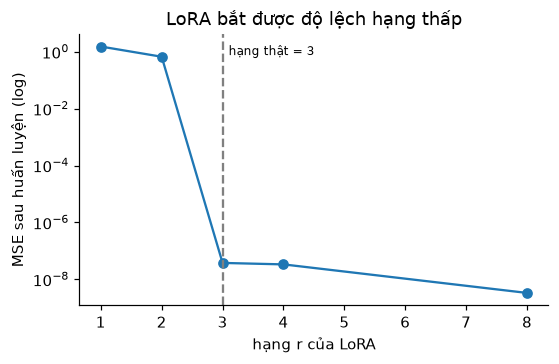

{1: '1.52e+00', 2: '6.65e-01', 3: '3.77e-08', 4: '3.35e-08', 8: '3.33e-09'}
Số tham số: LoRA r=3 → 288 so với tinh chỉnh toàn bộ → 2304


In [4]:
set_seed(0)
d, hang_that = 48, 3
W0 = torch.randn(d, d) / math.sqrt(d)
delta = (torch.randn(d, hang_that) @ torch.randn(hang_that, d)) / math.sqrt(d)      # hạng đúng bằng 3
Wstar = W0 + delta
X = torch.randn(2000, d); Y = X @ Wstar.T

ket_qua = {}
for r in [1, 2, 3, 4, 8]:
    base = nn.Linear(d, d, bias=False); base.weight.data.copy_(W0)
    m = LoRALinear(base, r=r, alpha=r)                       # scale = 1 để dễ so sánh
    opt = torch.optim.Adam([m.A, m.B], lr=0.02)
    for step in range(1500):
        loss = F.mse_loss(m(X), Y)
        opt.zero_grad(); loss.backward(); opt.step()
    ket_qua[r] = loss.item()

plt.figure(figsize=(5.5, 3.2))
plt.semilogy(list(ket_qua), list(ket_qua.values()), marker="o")
plt.axvline(hang_that, color="gray", ls="--"); plt.text(hang_that + .1, max(ket_qua.values()) / 2, "hạng thật = 3", fontsize=8)
plt.xlabel("hạng r của LoRA"); plt.ylabel("MSE sau huấn luyện (log)"); plt.title("LoRA bắt được độ lệch hạng thấp"); plt.show()
print({r: f"{v:.2e}" for r, v in ket_qua.items()})
print(f"Số tham số: LoRA r=3 → {3 * (d + d)} so với tinh chỉnh toàn bộ → {d * d}")

Với $r<3$ lỗi còn lớn (không đủ chỗ biểu diễn); từ $r=3$ trở lên lỗi giảm sâu về gần 0. Trong thực tế, các nghiên cứu cho thấy *độ lệch cần học để thích nghi một mô hình lớn sang tác vụ mới thường có hạng nội tại thấp* — nên $r=8$–$64$ thường đủ, dù ma trận gốc có hàng nghìn chiều. Đó là lý do LoRA hiệu quả.

**Quy mô tiết kiệm:** một ma trận $896\times896$ (kích thước ẩn của Qwen2.5-0.5B) có 802.816 tham số; LoRA $r=16$ chỉ cần $16\times(896+896)=28.672$ — ≈ 3,6%.

## 3. LoRA với `peft` trên LLM nhỏ: phân loại cảm xúc UIT-VSFC

Bây giờ áp dụng thật: tinh chỉnh **Qwen2.5-0.5B-Instruct** (Apache-2.0) để phân loại cảm xúc, trên cùng dữ liệu thật UIT-VSFC ở Bài 10, để *so sánh công bằng* với PhoBERT. Thiết kế:

- **Định dạng:** như Bài 13 — cho mô hình chọn đáp án A/B/C (A: tích cực, B: tiêu cực, C: trung tính). Ta huấn luyện nó sinh **đúng chữ cái** theo mẫu hội thoại; suy luận đọc xác suất của ba chữ cái ở token kế tiếp.
- **LoRA:** hạng $r=16$, $\alpha=32$, áp lên mọi lớp tuyến tính của khối Transformer (`q,k,v,o,gate,up,down`). Adapter giữ ở fp32, trọng số gốc ở fp16.
- **Tiết kiệm bộ nhớ (hai thứ):** (a) chỉ tính logit ở **vài vị trí cuối** (`logits_to_keep`) thay vì toàn bộ từ điển 152 nghìn token ở mọi vị trí; (b) **gradient checkpointing** để không giữ kích hoạt của mọi lớp. Mục 3.0 đo cả hai trước khi chọn kích thước batch.

In [5]:
MODEL = "Qwen/Qwen2.5-0.5B-Instruct"
MAX_TRAIN = 4000        # số mẫu huấn luyện (None = toàn bộ 11.426; mất lâu hơn nhiều)
EPOCHS, BATCH, LR = 1, 16, 2e-4
CHAY_LORA = device == "cuda"
if not CHAY_LORA:
    print("Không có GPU: bỏ qua mục 3 (huấn luyện LoRA trên CPU rất chậm). Bạn vẫn đọc được kết quả đã lưu trong notebook.")

if CHAY_LORA:
    ds = load_dataset("uitnlp/vietnamese_students_feedback", revision="refs/convert/parquet")
    names = ds["train"].features["sentiment"].names                # ['negative', 'neutral', 'positive']
    CHU = {"positive": "A", "negative": "B", "neutral": "C"}
    def to_df(split):
        d = ds[split].to_pandas()
        return pd.DataFrame({"text": d["sentence"], "y": d["sentiment"].map(lambda i: CHU[names[i]])})
    train, valid, test = to_df("train"), to_df("validation"), to_df("test")
    if MAX_TRAIN:
        train = train.sample(MAX_TRAIN, random_state=SEED).reset_index(drop=True)
    print("train/valid/test =", len(train), len(valid), len(test), "| phân phối nhãn train:", train["y"].value_counts(normalize=True).round(3).to_dict())

train/valid/test = 4000 1583 3166 | phân phối nhãn train: {'A': 0.495, 'B': 0.464, 'C': 0.042}


In [6]:
if CHAY_LORA:
    tok = AutoTokenizer.from_pretrained(MODEL)
    HE = "Bạn là bộ phân loại cảm xúc cho phản hồi của sinh viên bằng tiếng Việt."
    def prompt(text):
        msgs = [{"role": "system", "content": HE},
                {"role": "user", "content": f"Phân loại cảm xúc của phản hồi sau.\nPhản hồi: {text}\nChọn một đáp án:\nA. tích cực\nB. tiêu cực\nC. trung tính\nChỉ trả lời bằng một chữ cái."}]
        return tok.apply_chat_template(msgs, tokenize=False, add_generation_prompt=True)

    letter_id = {c: tok.encode(c, add_special_tokens=False)[0] for c in "ABC"}
    IM_END = tok.convert_tokens_to_ids("<|im_end|>")
    print("id các chữ cái:", letter_id, "| độ dài prompt:", len(tok(prompt("thầy dạy dễ hiểu ."))["input_ids"]), "token")

    @torch.no_grad()
    def du_doan(model, texts, bs=64):
        """Đệm TRÁI để token cuối của mọi dòng là token cuối của prompt; chỉ lấy logit vị trí cuối."""
        model.eval(); out = []
        ids3 = [letter_id[c] for c in "ABC"]
        for i in range(0, len(texts), bs):
            ps = [tok(prompt(t), add_special_tokens=False)["input_ids"] for t in texts[i:i + bs]]
            L = max(map(len, ps))
            ids = torch.full((len(ps), L), tok.pad_token_id); m = torch.zeros((len(ps), L), dtype=torch.long)
            for j, p in enumerate(ps):
                ids[j, L - len(p):] = torch.tensor(p); m[j, L - len(p):] = 1
            with torch.autocast("cuda", dtype=torch.float16):
                lg = model(input_ids=ids.to(device), attention_mask=m.to(device), logits_to_keep=1).logits[:, -1].float()
            out += ["ABC"[k] for k in lg[:, ids3].argmax(1).cpu().tolist()]
        return out

    def danh_gia(model, df, ten):
        p = du_doan(model, df["text"].tolist())
        return {"mô hình": ten, "accuracy": round(accuracy_score(df["y"], p), 3), "macro-F1": round(f1_score(df["y"], p, average="macro"), 3)}, p

id các chữ cái: {'A': 32, 'B': 33, 'C': 34} | độ dài prompt: 80 token


### 3.0 Đo bộ nhớ trước khi huấn luyện (đừng đoán)

**Kích hoạt** (đầu ra trung gian của từng lớp, cần giữ lại cho lan truyền ngược) tăng theo *kích thước batch × độ dài chuỗi*. Hai cách giảm: **batch nhỏ hơn**, hoặc **gradient checkpointing** — không giữ kích hoạt của mọi lớp mà *tính lại* chúng khi cần (đổi thêm một lượt tính xuôi lấy bộ nhớ). Ta đo bốn cấu hình trên dữ liệu giả dài 112 token (cỡ prompt + một câu phản hồi dài của bài này); mỗi cấu hình dựng mô hình + LoRA mới và chạy 3 bước:

In [7]:
if CHAY_LORA:
    def do_bo_nho(bs, ckpt, L=112, buoc=3):
        """Dựng mô hình + LoRA mới, chạy vài bước huấn luyện trên token giả; trả về (VRAM đỉnh GB, giây/bước)."""
        import gc
        torch.cuda.empty_cache(); torch.cuda.reset_peak_memory_stats()
        b = AutoModelForCausalLM.from_pretrained(MODEL, dtype=torch.float16).to(device)
        if ckpt:
            b.gradient_checkpointing_enable(gradient_checkpointing_kwargs={"use_reentrant": False})
            b.enable_input_require_grads()            # gốc bị đóng băng nên phải cho đầu vào embedding có gradient để đường checkpoint chạy
        m = get_peft_model(b, LoraConfig(r=16, lora_alpha=32, lora_dropout=0.05, task_type="CAUSAL_LM",
                                         target_modules=["q_proj", "k_proj", "v_proj", "o_proj", "gate_proj", "up_proj", "down_proj"]))
        for _, q in m.named_parameters():
            if q.requires_grad:
                q.data = q.data.float()
        m.train(); ps = [q for q in m.parameters() if q.requires_grad]
        o = torch.optim.AdamW(ps, lr=1e-4); sc = torch.amp.GradScaler("cuda")
        x = torch.randint(0, 1000, (bs, L), device=device); am = torch.ones_like(x); ts = []
        for _ in range(buoc):
            torch.cuda.synchronize(); t0 = time.time()
            with torch.autocast("cuda", dtype=torch.float16):
                lg = m(input_ids=x, attention_mask=am, use_cache=False, logits_to_keep=3).logits
            loss = F.cross_entropy(lg[:, :2].reshape(-1, lg.size(-1)).float(), x[:, -2:].reshape(-1))
            o.zero_grad(set_to_none=True); sc.scale(loss).backward(); sc.step(o); sc.update()
            torch.cuda.synchronize(); ts.append(time.time() - t0)
        peak = torch.cuda.max_memory_allocated() / 1e9
        del m, b, o, ps, lg, loss; gc.collect(); torch.cuda.empty_cache()
        return peak, float(np.mean(ts[1:]))

    kq = []
    for bs, ckpt in [(16, False), (8, False), (16, True), (8, True)]:
        peak, dt = do_bo_nho(bs, ckpt)
        kq.append({"batch": bs, "gradient checkpointing": "bật" if ckpt else "tắt", "VRAM đỉnh (GB)": round(peak, 2),
                   "giây/bước": round(dt, 2), "so với VRAM vật lý": f"VƯỢT {vram:.2f} GB" if peak > vram else "vừa"})
    display(pd.DataFrame(kq).set_index(["batch", "gradient checkpointing"]))

,,VRAM đỉnh (GB),giây/bước,so với VRAM vật lý
batch,gradient checkpointing,,,
16,tắt,4.33,1.79,VƯỢT 4.29 GB
8,tắt,2.73,0.34,vừa
16,bật,1.38,0.80,vừa
8,bật,1.29,0.59,vừa


**Đọc kết quả.** Khi *không* dùng checkpointing, batch 16 có đỉnh vượt VRAM vật lý của card: trên Windows, trình điều khiển không báo lỗi hết bộ nhớ mà **lặng lẽ tràn sang RAM hệ thống**, nên bước huấn luyện chậm đi rất nhiều mà không có cảnh báo nào — đây là lý do phải *đo*, không chỉ tin vào việc "chạy được". Giảm batch xuống 8 giúp vừa; bật checkpointing giảm đỉnh mạnh hơn (ở cả batch 8 và 16) và cho phép dùng batch 16. Đỉnh thật khi huấn luyện (mục 3.3, ≈ 1,7 GB) cao hơn số đo giả (≈ 1,4 GB) vì một batch thật chứa câu dài hơn 112 token. Ta chọn **batch 16 + checkpointing**.

### 3.1 Mốc so sánh: zero-shot (chưa tinh chỉnh)

In [8]:
if CHAY_LORA:
    base = AutoModelForCausalLM.from_pretrained(MODEL, dtype=torch.float16).to(device)
    n_goc = sum(p.numel() for p in base.parameters())
    t0 = time.time()
    r_zero, _ = danh_gia(base, test, "Qwen2.5-0.5B zero-shot")
    print(r_zero, f"| {time.time() - t0:.0f}s cho {len(test)} câu")

{'mô hình': 'Qwen2.5-0.5B zero-shot', 'accuracy': 0.819, 'macro-F1': 0.593} | 33s cho 3166 câu


### 3.2 Gắn LoRA và đếm tham số

In [9]:
if CHAY_LORA:
    base.gradient_checkpointing_enable(gradient_checkpointing_kwargs={"use_reentrant": False})   # chỉ có tác dụng ở chế độ train()
    base.enable_input_require_grads()
    cfg = LoraConfig(r=16, lora_alpha=32, lora_dropout=0.05, task_type="CAUSAL_LM",
                     target_modules=["q_proj", "k_proj", "v_proj", "o_proj", "gate_proj", "up_proj", "down_proj"])
    model = get_peft_model(base, cfg)
    for _, p in model.named_parameters():
        if p.requires_grad:
            p.data = p.data.float()                              # adapter ở fp32 cho ổn định
    model.print_trainable_parameters()
    n_train = sum(p.numel() for p in model.parameters() if p.requires_grad)
    print(f"→ huấn luyện {n_train / 1e6:.1f} triệu tham số = {n_train / n_goc:.2%} của mô hình; ước tính trạng thái tối ưu+gradient ≈ {gb(n_train, 16) * 1000:.0f} MB")

trainable params: 8,798,208 || all params: 502,830,976 || trainable%: 1.7497
→ huấn luyện 8.8 triệu tham số = 1.78% của mô hình; ước tính trạng thái tối ưu+gradient ≈ 141 MB


### 3.3 Huấn luyện

Vòng lặp giống Bài 10, khác: (a) chỉ tối ưu tham số adapter; (b) mục tiêu là sinh đúng chữ cái và `<|im_end|>` (2 token cuối); (c) `logits_to_keep=3` và `use_cache=False` (bộ đệm KV không dùng khi huấn luyện, và không tương thích với checkpointing); (d) gradient checkpointing đã bật ở mục 3.2.

In [10]:
if CHAY_LORA:
    def ma_hoa(df):
        return [tok(prompt(t), add_special_tokens=False)["input_ids"] + [letter_id[y], IM_END] for t, y in zip(df["text"], df["y"])]

    def collate(b):
        L = max(map(len, b))
        ids = torch.full((len(b), L), tok.pad_token_id); m = torch.zeros((len(b), L), dtype=torch.long)
        for i, x in enumerate(b):
            ids[i, L - len(x):] = torch.tensor(x); m[i, L - len(x):] = 1
        return ids, m

    data = ma_hoa(train)
    params = [p for p in model.parameters() if p.requires_grad]
    opt = torch.optim.AdamW(params, lr=LR, weight_decay=0.0)
    steps = EPOCHS * (len(data) // BATCH)
    sched = get_linear_schedule_with_warmup(opt, int(0.05 * steps), steps)
    scaler = torch.amp.GradScaler("cuda")
    g = np.random.default_rng(SEED)
    torch.cuda.reset_peak_memory_stats()
    model.train(); t0 = time.time(); lich_su = []
    for ep in range(EPOCHS):
        perm = g.permutation(len(data))
        for s in range(0, len(perm) - BATCH + 1, BATCH):
            ids, m = collate([data[i] for i in perm[s:s + BATCH]])
            with torch.autocast("cuda", dtype=torch.float16):
                logits = model(input_ids=ids.to(device), attention_mask=m.to(device), use_cache=False, logits_to_keep=3).logits       # (B, 3, V)
            loss = F.cross_entropy(logits[:, :2].reshape(-1, logits.size(-1)).float(), ids[:, -2:].reshape(-1).to(device))
            opt.zero_grad(set_to_none=True); scaler.scale(loss).backward(); scaler.unscale_(opt)
            torch.nn.utils.clip_grad_norm_(params, 1.0)
            scaler.step(opt); scaler.update(); sched.step()
            lich_su.append(loss.item())
            if (s // BATCH) % 50 == 0:
                print(f"bước {s // BATCH:4d}/{steps} | loss {np.mean(lich_su[-50:]):.4f} | {time.time() - t0:.0f}s", flush=True)
    t_train = time.time() - t0
    vram_peak = torch.cuda.max_memory_allocated() / 1e9
    print(f"\nHuấn luyện xong: {t_train / 60:.1f} phút | VRAM đỉnh {vram_peak:.2f} GB" + (f"  ⚠ vượt VRAM vật lý {vram:.2f} GB: đã tràn sang RAM hệ thống, thời gian trên không còn đại diện" if vram_peak > vram else ""))

bước    0/250 | loss 0.4364 | 1s


bước   50/250 | loss 0.2475 | 46s


bước  100/250 | loss 0.1324 | 90s


bước  150/250 | loss 0.1186 | 134s


bước  200/250 | loss 0.1118 | 178s



Huấn luyện xong: 3.7 phút | VRAM đỉnh 1.73 GB


### 3.4 Đánh giá: trong miền và ngoài miền

In [11]:
if CHAY_LORA:
    r_lora, p_lora = danh_gia(model, test, "Qwen2.5-0.5B + LoRA")
    hard = load_hard()
    hard_y = hard["label"].map({"tích cực": "A", "tiêu cực": "B", "trung tính": "C"})
    hard_df = pd.DataFrame({"text": hard["text"], "y": hard_y})
    with model.disable_adapter():                                    # tắt adapter = mô hình gốc
        r_zero_h, _ = danh_gia(model, hard_df, "Qwen2.5-0.5B zero-shot")
    r_lora_h, _ = danh_gia(model, hard_df, "Qwen2.5-0.5B + LoRA")
    display(pd.DataFrame([{**r_zero, "bộ": "UIT-VSFC test (trong miền)"}, {**r_lora, "bộ": "UIT-VSFC test (trong miền)"},
                          {**r_zero_h, "bộ": "40 câu khó sản phẩm (ngoài miền)"}, {**r_lora_h, "bộ": "40 câu khó sản phẩm (ngoài miền)"}]).set_index(["bộ", "mô hình"]))
    print(classification_report(test["y"], p_lora, target_names=["A tích cực", "B tiêu cực", "C trung tính"], digits=3))

accuracy  macro-F1
bộ                               mô hình                                   
UIT-VSFC test (trong miền)       Qwen2.5-0.5B zero-shot     0.819     0.593
                                 Qwen2.5-0.5B + LoRA        0.927     0.810
40 câu khó sản phẩm (ngoài miền) Qwen2.5-0.5B zero-shot     0.625     0.474
                                 Qwen2.5-0.5B + LoRA        0.650     0.577

              precision    recall  f1-score   support

  A tích cực      0.949     0.945     0.947      1590
  B tiêu cực      0.930     0.961     0.945      1409
C trung tính      0.622     0.473     0.537       167

    accuracy                          0.927      3166
   macro avg      0.834     0.793     0.810      3166
weighted avg      0.923     0.927     0.924      3166



**Đọc kết quả.**

- **Trong miền (UIT-VSFC test):** LoRA nâng macro-F1 từ 0,593 (zero-shot) lên ≈ 0,81 và accuracy từ 0,819 lên ≈ 0,93, dù chỉ huấn luyện 8,8 triệu tham số (≈ 1,75% mô hình) trên 4.000 mẫu (≈ 35% dữ liệu huấn luyện). Con số nằm giữa TF-IDF (0,721) và PhoBERT tinh chỉnh toàn bộ (0,840) của Bài 10: **gần PhoBERT nhưng chưa bằng**, trong khi mô hình gốc lớn gấp ≈ 3,7 lần (494 so với 135 triệu tham số).
- **Lớp hiếm vẫn là điểm yếu:** "trung tính" (C) chỉ chiếm ≈ 4% dữ liệu huấn luyện; recall chỉ ≈ 0,47 và F1 ≈ 0,54, trong khi hai lớp còn lại đều > 0,94. Accuracy 0,93 che đi điều này — vì vậy ta báo cáo macro-F1 và báo cáo theo lớp.
- **Ngoài miền (40 câu khó):** macro-F1 tăng 0,474 → 0,577 nhưng accuracy chỉ 0,625 → 0,650, tức đúng **một câu** (1/40 = 0,025). Với 40 câu, chênh lệch cỡ này nằm trong nhiễu; ta *không* kết luận LoRA tổng quát hóa tốt hơn sang miền sản phẩm (dữ liệu huấn luyện là phản hồi của sinh viên).
- **Độ lặp lại:** đây là một lần chạy, một seed. Cùng seed, cùng dữ liệu: lần chạy *không* bật checkpointing của chúng tôi cho macro-F1 0,792, còn ba lần chạy có checkpointing cho 0,806, 0,807 và 0,810. Chỉ đổi cách quản lý bộ nhớ đã làm điểm lệch cỡ 0,015, và huấn luyện không hoàn toàn tất định (ba lần chạy giống hệt nhau về cấu hình vẫn lệch nhau vài phần nghìn), nên hãy coi chênh lệch dưới ≈ 0,02 là chưa phân biệt được.

### 3.5 Lưu adapter, nạp lại, hợp nhất

In [12]:
if CHAY_LORA:
    OUT = ROOT / "outputs" / "lora-cam-xuc"
    OUT.mkdir(parents=True, exist_ok=True)
    model.save_pretrained(OUT)
    kich_thuoc = sum(f.stat().st_size for f in OUT.iterdir()) / 1e6
    print("Tệp adapter:", sorted(f.name for f in OUT.iterdir()), f"→ {kich_thuoc:.0f} MB (mô hình gốc fp16 ≈ {n_goc * 2 / 1e6:.0f} MB)")

    mau = test["text"].tolist()[:200]
    p_truoc = du_doan(model, mau)
    # nạp lại: mô hình gốc sạch + adapter từ đĩa
    del model, base; torch.cuda.empty_cache()
    base2 = AutoModelForCausalLM.from_pretrained(MODEL, dtype=torch.float16).to(device)
    model2 = PeftModel.from_pretrained(base2, OUT)
    p_sau = du_doan(model2, mau)
    print("Nạp lại adapter cho dự đoán giống hệt:", p_truoc == p_sau)

    m400 = test["text"].tolist()[:400]
    t0 = time.time(); p_adapter = du_doan(model2, m400); t_adapter = time.time() - t0
    merged = model2.merge_and_unload()                               # gộp ΔW vào W0
    t0 = time.time(); p_gop = du_doan(merged, m400); t_merged = time.time() - t0
    print(f"Suy luận 400 câu: có adapter {t_adapter:.1f}s | đã hợp nhất {t_merged:.1f}s")
    print(f"Dự đoán sau hợp nhất trùng với trước hợp nhất: {np.mean(np.array(p_gop) == np.array(p_adapter)):.1%} (khác biệt nhỏ do làm tròn fp16)")

Tệp adapter: ['README.md', 'adapter_config.json', 'adapter_model.safetensors'] → 35 MB (mô hình gốc fp16 ≈ 988 MB)


Nạp lại adapter cho dự đoán giống hệt: True


Suy luận 400 câu: có adapter 6.3s | đã hợp nhất 4.2s
Dự đoán sau hợp nhất trùng với trước hợp nhất: 100.0% (khác biệt nhỏ do làm tròn fp16)


## 4. Lượng tử hóa: suy luận nhẹ hơn, nhanh hơn — và cái giá

**Lượng tử hóa** lưu trọng số (và/hoặc kích hoạt) bằng số nguyên ít bit (int8, int4) thay vì số thực 16/32 bit: bộ nhớ nhỏ hơn, thường nhanh hơn trên CPU. Đổi lại có **sai số làm tròn**. PyTorch hỗ trợ **lượng tử hóa động int8** cho các lớp tuyến tính chỉ bằng một lời gọi; ta thử trên PhoBERT đã tinh chỉnh ở Bài 10 (nếu bạn đã chạy bài đó) và đo **cả ba thứ**: kích thước, tốc độ, chất lượng *theo từng lớp*.

In [13]:
PHOBERT_DIR = ROOT / "outputs" / "phobert-cam-xuc"
CHAY_QUANT = PHOBERT_DIR.exists()
if not CHAY_QUANT:
    print("Chưa có outputs/phobert-cam-xuc — hãy chạy Bài 10 để thử mục này. (Bỏ qua.)")
else:
    torch.set_num_threads(max(1, min(8, os.cpu_count() or 4)))
    tkq = AutoTokenizer.from_pretrained(PHOBERT_DIR)
    m32 = AutoModelForSequenceClassification.from_pretrained(PHOBERT_DIR).eval()                  # CPU, fp32
    m8 = torch.ao.quantization.quantize_dynamic(m32, {nn.Linear}, dtype=torch.qint8)             # int8 cho mọi lớp Linear
    dsq = load_dataset("uitnlp/vietnamese_students_feedback", revision="refs/convert/parquet")["test"].to_pandas()
    nhan = ["tiêu cực", "trung tính", "tích cực"]
    N = 1500
    yq = dsq["sentiment"].map(lambda i: nhan[i]).values[:N]
    tq = dsq["sentence"].tolist()[:N]

    def kich_thuoc_mb(m):
        b = io.BytesIO(); torch.save(m.state_dict(), b); return b.tell() / 1e6

    @torch.no_grad()
    def chay(m, texts, bs=32):
        preds, t0 = [], time.time()
        for i in range(0, len(texts), bs):
            enc = tkq([segment(t) for t in texts[i:i + bs]], padding=True, truncation=True, max_length=64, return_tensors="pt")
            preds += m(**enc).logits.argmax(-1).tolist()
        return [m32.config.id2label[i] for i in preds], time.time() - t0

    rows, preds_q = [], {}
    for ten, m in [("fp32", m32), ("int8 (động)", m8)]:
        p, dt = chay(m, tq)
        preds_q[ten] = p
        rows.append({"phiên bản": ten, "kích thước (MB)": round(kich_thuoc_mb(m)), "câu/giây (CPU)": round(len(tq) / dt, 1),
                     "accuracy": round(accuracy_score(yq, p), 3), "macro-F1": round(f1_score(yq, p, average="macro"), 3)})
    display(pd.DataFrame(rows).set_index("phiên bản"))
    print(f"Đồng thuận dự đoán fp32 vs int8: {np.mean(np.array(preds_q['fp32']) == np.array(preds_q['int8 (động)'])):.3f} | số mẫu mỗi lớp trong {N} câu đầu:", dict(pd.Series(yq).value_counts()))

,kích thước (MB),câu/giây (CPU),accuracy,macro-F1
phiên bản,,,,
fp32,540,34.3,0.935,0.833
int8 (động),284,53.1,0.915,0.695


Đồng thuận dự đoán fp32 vs int8: 0.958 | số mẫu mỗi lớp trong 1500 câu đầu: {'tích cực': np.int64(766), 'tiêu cực': np.int64(652), 'trung tính': np.int64(82)}


In [14]:
if CHAY_QUANT:
    out = {}
    for ten in ["fp32", "int8 (động)"]:
        _, r, f, _ = precision_recall_fscore_support(yq, preds_q[ten], labels=nhan, zero_division=0)
        out[ten] = {f"F1 {l}": round(x, 3) for l, x in zip(nhan, f)} | {f"recall {l}": round(x, 3) for l, x in zip(nhan, r)}
    display(pd.DataFrame(out).T)

,F1 tiêu cực,F1 trung tính,F1 tích cực,recall tiêu cực,recall trung tính,recall tích cực
fp32,0.952,0.596,0.951,0.966,0.512,0.953
int8 (động),0.943,0.208,0.935,0.969,0.122,0.954


**Đọc kết quả (4.1).**

- **Kích thước** giảm 540 → 284 MB (−47%), không phải 4 lần: `quantize_dynamic` chỉ đổi các lớp `Linear`, còn bảng embedding từ vựng (≈ 64 nghìn từ × 768 chiều ≈ 49 triệu tham số ≈ 197 MB) vẫn ở fp32.
- **Tốc độ** trên CPU tăng ≈ 1,5 lần (xem cột câu/giây).
- **Chất lượng:** accuracy chỉ giảm 0,935 → 0,915, nhưng **macro-F1 giảm 0,833 → 0,695**. Thiệt hại dồn vào lớp hiếm: recall "trung tính" 0,512 → 0,122 (≈ 42 → 10 trong 82 câu), trong khi F1 của hai lớp lớn gần như giữ nguyên (0,952 → 0,943 và 0,951 → 0,935). Nếu chỉ nhìn accuracy, ta sẽ kết luận "mất 2 điểm, chấp nhận được" và bỏ sót việc mô hình gần như không còn nhận ra câu trung tính.

### 4.2 Lượng tử hóa từng phần: sai số nằm ở đâu?

Nếu áp int8 cho toàn bộ gây hại, có thể chỉ cần áp cho *một phần* mô hình? Ta thử: chỉ khối FFN, chỉ khối attention (cả 12 lớp), rồi chỉ nửa dưới (6 lớp đầu) hoặc nửa trên (6 lớp cuối). Mỗi biến thể đo lại cả bốn thứ: kích thước, tốc độ, accuracy/macro-F1 và recall lớp "trung tính".

In [15]:
if CHAY_QUANT:
    import copy
    # quantize_dynamic chỉ đổi các module CON của đối tượng được truyền vào: đưa thẳng một nn.Linear trần thì nó không làm gì.
    # Bọc trong nn.Sequential để mọi Linear (kể cả bên trong, ví dụ q/k/v của attention) đều được đổi.
    q8 = lambda mod: torch.ao.quantization.quantize_dynamic(nn.Sequential(mod), {nn.Linear}, dtype=torch.qint8)[0]

    def luong_tu_hoa(lop=range(12), phan=("ffn", "attention")):
        """Bản sao của m32 với int8 (động) chỉ ở các lớp encoder `lop`, và chỉ ở khối `phan`."""
        m = copy.deepcopy(m32)
        for i in lop:
            L = m.roberta.encoder.layer[i]
            if "ffn" in phan:
                L.intermediate = q8(L.intermediate); L.output.dense = q8(L.output.dense)
            if "attention" in phan:
                L.attention.self = q8(L.attention.self); L.attention.output.dense = q8(L.attention.output.dense)
        return m

    cau_hinh = [("fp32 (gốc)", m32), ("int8 toàn bộ (mục 4.1)", m8),
                ("chỉ FFN, 12 lớp", luong_tu_hoa(phan=("ffn",))), ("chỉ attention, 12 lớp", luong_tu_hoa(phan=("attention",))),
                ("cả hai, 6 lớp đầu", luong_tu_hoa(range(0, 6))), ("cả hai, 6 lớp cuối", luong_tu_hoa(range(6, 12)))]
    rows2 = []
    for ten, m in cau_hinh:
        p, dt = chay(m, tq)
        _, r, _, _ = precision_recall_fscore_support(yq, p, labels=nhan, zero_division=0)
        rows2.append({"phiên bản": ten, "kích thước (MB)": round(kich_thuoc_mb(m)), "câu/giây (CPU)": round(len(tq) / dt, 1),
                      "accuracy": round(accuracy_score(yq, p), 3), "macro-F1": round(f1_score(yq, p, average="macro"), 3),
                      "recall trung tính": round(r[nhan.index("trung tính")], 3)})
    display(pd.DataFrame(rows2).set_index("phiên bản"))

,kích thước (MB),câu/giây (CPU),accuracy,macro-F1,recall trung tính
phiên bản,,,,,
fp32 (gốc),540,33.9,0.935,0.833,0.512
int8 toàn bộ (mục 4.1),284,53.4,0.915,0.695,0.122
"chỉ FFN, 12 lớp",370,45.2,0.917,0.714,0.159
"chỉ attention, 12 lớp",455,37.9,0.934,0.835,0.524
"cả hai, 6 lớp đầu",413,41.8,0.929,0.830,0.537
"cả hai, 6 lớp cuối",413,42.2,0.923,0.729,0.183


**Đọc kết quả (4.2).**

- **Khối FFN gây gần như toàn bộ thiệt hại.** Chỉ lượng tử hóa FFN (12 lớp) giảm 540 → 370 MB nhưng macro-F1 tụt 0,833 → 0,714 và recall "trung tính" 0,512 → 0,159 — gần bằng int8 toàn bộ (0,695). Chỉ lượng tử hóa attention thì macro-F1 ≈ 0,835 (không mất so với fp32), nhưng cũng chỉ giảm 540 → 455 MB. Phần lợi và phần hại nằm chung một chỗ: FFN chiếm 2/3 số trọng số `Linear` của mỗi lớp (≈ 4,7 triệu so với 2,4 triệu của attention) nên cho nhiều lợi nhất, đồng thời là nơi sai số làm tròn gây hại. (Vì sao FFN nhạy hơn thì bài này không kiểm tra; một giả thuyết thường gặp là kích hoạt trong FFN có giá trị ngoại lai làm thang int8 kém chính xác.)
- **Vị trí lớp cũng quan trọng.** Làm cả hai khối nhưng chỉ ở **6 lớp đầu** thì macro-F1 ≈ 0,830 (gần như không mất) ở 413 MB, còn **6 lớp cuối** chỉ ≈ 0,729 (recall "trung tính" ≈ 0,18) — cùng dung lượng tiết kiệm nhưng kết quả rất khác. Cái giá phụ thuộc vào *phần nào* của mô hình bị lượng tử hóa, không chỉ bao nhiêu.
- **Bài học thực hành:** (1) đừng mặc định áp lượng tử hóa cho cả mô hình — thử từng phần và đo theo lớp trước khi chọn; (2) accuracy chỉ nhích 1–2 điểm ngay cả ở cấu hình tệ nhất (0,935 → 0,915) trong khi macro-F1 mất ≈ 0,14: cái giá nằm ở lớp hiếm; (3) đây là kết quả của **một checkpoint, một lần chạy** — đừng suy ra quy luật cho mô hình khác, hãy đo trên mô hình của bạn.

## 5. Chọn gì? — bản đồ quyết định

Đến đây khóa học đã cho bạn một "hộp công cụ" đầy đủ. Bảng dưới tổng hợp **số đo thật** trên cùng một bài toán (UIT-VSFC, 3 lớp) từ các bài trước và bài này (một lần chạy, một seed, RTX 3050 4 GB; riêng LoRA là cấu hình rút gọn ở mục 3):

In [16]:
dong = [
    {"cách làm": "TF-IDF + Logistic Regression (Bài 10)", "tham số huấn luyện": "hệ số tuyến tính", "huấn luyện": "≈ 2 giây (CPU)", "VRAM": "0", "macro-F1 test": 0.721},
    {"cách làm": "PhoBERT tinh chỉnh toàn bộ (Bài 10)", "tham số huấn luyện": "135 triệu", "huấn luyện": "≈ 3,4 phút (GPU)", "VRAM": "≈ 3,1 GB", "macro-F1 test": 0.840},
]
if CHAY_LORA:
    dong = [{"cách làm": "Qwen2.5-0.5B zero-shot (mục 3.1)", "tham số huấn luyện": "0", "huấn luyện": "—", "VRAM": "≈ 1 GB (suy luận)", "macro-F1 test": r_zero["macro-F1"]}] + dong
    dong.append({"cách làm": f"Qwen2.5-0.5B + LoRA r=16, {len(train):,} mẫu (mục 3)", "tham số huấn luyện": f"{n_train / 1e6:.1f} triệu", "huấn luyện": f"≈ {t_train / 60:.1f} phút (GPU)",
                 "VRAM": f"≈ {vram_peak:.1f} GB", "macro-F1 test": r_lora["macro-F1"]})
pd.DataFrame(dong).set_index("cách làm")

,tham số huấn luyện,huấn luyện,VRAM,macro-F1 test
cách làm,,,,
Qwen2.5-0.5B zero-shot (mục 3.1),0,—,≈ 1 GB (suy luận),0.593
TF-IDF + Logistic Regression (Bài 10),hệ số tuyến tính,≈ 2 giây (CPU),0,0.721
PhoBERT tinh chỉnh toàn bộ (Bài 10),135 triệu,"≈ 3,4 phút (GPU)","≈ 3,1 GB",0.840
"Qwen2.5-0.5B + LoRA r=16, 4,000 mẫu (mục 3)",8.8 triệu,≈ 3.7 phút (GPU),≈ 1.7 GB,0.810


**Cách chọn thực dụng:**

| Tình huống | Gợi ý | Lý do |
|---|---|---|
| Ít dữ liệu nhãn, bài toán đơn giản, cần chạy rẻ/nhanh | **TF-IDF + tuyến tính** (Bài 3) | baseline mạnh, huấn luyện giây, giải thích được |
| Có vài nghìn mẫu nhãn tiếng Việt, cần chất lượng cao, suy luận rẻ | **PhoBERT tinh chỉnh** (Bài 10) | thường tốt nhất cho phân loại/NER tiếng Việt; có thể lượng tử hóa |
| Nhiều tác vụ khác nhau, cần *tạo sinh* hoặc theo chỉ dẫn, có GPU vừa phải | **LLM nhỏ + LoRA** (bài này) | một mô hình gốc, nhiều adapter nhỏ; nhưng mô hình gốc lớn gấp ≈ 3,7 lần PhoBERT và trong thí nghiệm của bài này (4.000 mẫu) điểm thấp hơn PhoBERT (xem bảng trên) |
| Chưa có nhãn, tác vụ thay đổi liên tục, ngữ cảnh dài | **Prompt LLM lớn qua API** (Bài 13) | không cần dữ liệu nhãn; đổi lại chi phí theo token, quyền riêng tư dữ liệu, độ trễ |
| Trả lời dựa trên tài liệu riêng thường xuyên đổi | **RAG** (Bài 12–13) | cập nhật bằng cách đổi kho tài liệu, không cần huấn luyện lại |

Luôn bắt đầu từ cách **rẻ nhất có thể** và chỉ leo thang khi *đo được* rằng nó chưa đạt yêu cầu.

## 6. Các kỹ thuật liên quan (không chạy trong bài)

- **QLoRA**: LoRA trên mô hình gốc đã lượng tử hóa 4-bit (thư viện `bitsandbytes`), cho phép tinh chỉnh mô hình vài tỉ tham số trên một GPU nhỏ. Cần hỗ trợ CUDA/bitsandbytes tương thích hệ điều hành của bạn.
- **Tinh chỉnh theo chỉ dẫn (SFT) và học từ phản hồi (RLHF/DPO)**: các bước biến mô hình ngôn ngữ thô thành trợ lý; LoRA thường dùng cho SFT.
- **Chưng cất tri thức (distillation)**: huấn luyện mô hình nhỏ bắt chước đầu ra của mô hình lớn để chạy rẻ hơn.
- **ONNX Runtime / TensorRT / vLLM**: bộ máy suy luận tối ưu; đáng dùng khi triển khai quy mô lớn.
- **Lượng tử hóa sau huấn luyện int4/GPTQ/AWQ**: nhỏ hơn nữa, đánh đổi chất lượng nhiều hơn — *luôn* đo trên nhiệm vụ của bạn.

## 7. Tổng kết

- Tinh chỉnh toàn bộ tốn ≈ 16 byte/tham số; LoRA đóng băng gốc và chỉ huấn luyện cặp ma trận hạng thấp nên phần trọng số/gradient/Adam nhỏ — nhưng **kích hoạt** mới quyết định có vừa VRAM hay không. **Hãy đo** (mục 3.0), đừng đoán: cùng một cấu hình có thể vừa hoặc tràn, và trên Windows tràn VRAM chỉ làm chậm chứ không báo lỗi.
- Gradient checkpointing đổi thêm một lượt tính xuôi lấy bộ nhớ; với bài này nó là khác biệt giữa huấn luyện chậm vì tràn VRAM và huấn luyện bình thường.
- LoRA: $\Delta W=\frac{\alpha}{r}BA$, $B$ khởi tạo 0, có thể **hợp nhất** để suy luận không tốn thêm.
- Adapter chỉ vài chục MB, dễ lưu/chia sẻ từng tác vụ trên cùng một mô hình gốc.
- **Lượng tử hóa** giảm kích thước và tăng tốc nhưng có sai số; *kiểm tra theo từng lớp*, nhất là lớp hiếm — accuracy tổng thể có thể che giấu sự sụt giảm. Cái giá phụ thuộc vào *phần nào* của mô hình bị lượng tử hóa (khối FFN hay attention, lớp nào): thử từng phần và đo.
- Chọn công cụ theo dữ liệu, ngân sách, độ trễ và quyền riêng tư; bắt đầu từ cách rẻ nhất rồi đo.

## Bài tập

1. **(Dễ)** Thay `r=16` bằng `r=4` và `r=64` (với `MAX_TRAIN=2000` để nhanh). Số tham số huấn luyện, macro-F1 và thời gian thay đổi thế nào?
2. **(Dễ)** Chỉ áp LoRA lên `q_proj` và `v_proj` (cấu hình gốc của bài báo). So với áp lên mọi lớp tuyến tính.
3. **(Vừa)** Tăng `MAX_TRAIN` lên toàn bộ (11.426) và `EPOCHS=2`. Điểm có tiệm cận PhoBERT không? Chi phí thời gian?
4. **(Vừa)** Giữ nguyên lớp phân loại (`classifier`) ở fp32 và chỉ lượng tử hóa phần `roberta`. Kết quả có khác mục 4.1 không? Sau đó thử tập lớp khác ở mục 4.2 (lớp chẵn so với lớp lẻ, 3 lớp cuối...) và tìm cấu hình giảm dung lượng mà **không** làm tụt recall lớp "trung tính".
5. **(Khó)** Cài thêm **dropout trên $A$, $B$** và **khởi tạo kiểu rsLoRA** ($\alpha/\sqrt r$). So đường cong loss với bản mặc định.

<details>
<summary><b>Gợi ý đáp án</b></summary>

1. Số tham số tỉ lệ thuận với r (r=4 ≈ 2,2 triệu; r=64 ≈ 35 triệu). Thường điểm tăng nhanh từ r nhỏ lên vừa rồi bão hòa; thời gian thay đổi ít vì phần tính toán chủ yếu ở mô hình gốc.
2. Chỉ `q,v`: ít tham số hơn (≈ 1/4), điểm thường thấp hơn một chút; áp lên mọi lớp tuyến tính thường tốt hơn với cùng r.
3. Thêm dữ liệu giúp rõ rệt; so sánh cả thời gian — với PhoBERT cho phân loại thuần túy, mô hình LLM nhỏ + LoRA thường tốn tài nguyên hơn nhiều lần cho kết quả tương đương hoặc kém hơn.
4. Trên checkpoint của chúng tôi, giữ `classifier` ở fp32 **không thay đổi gì** (macro-F1 vẫn 0,695, recall "trung tính" vẫn 0,122): phỏng đoán "lớp phân loại là thủ phạm" là sai, và đó là lý do cần đo. Về tập lớp: chỉ lượng tử hóa các lớp chẵn (0, 2, ..., 10) cho macro-F1 ≈ 0,835 (không mất so với fp32) ở 413 MB; các lớp lẻ giảm còn ≈ 0,806; 6 lớp cuối ≈ 0,729. (Một lần chạy trên một checkpoint; trên mô hình của bạn số sẽ khác — hãy tự đo.)
5. `scale = alpha / math.sqrt(r)`; thường ổn định hơn khi r lớn.
</details>

**Tiếp theo →** quay lại [docs/DO_AN.md](../docs/DO_AN.md): chọn đề tài, và áp dụng bản đồ quyết định ở mục 5 để chọn phương pháp cho đồ án của bạn.

**Đọc thêm:** Hu và cộng sự, *LoRA: Low-Rank Adaptation of Large Language Models* (2021) · Dettmers và cộng sự, *QLoRA* (2023) · [tài liệu PEFT của Hugging Face](https://huggingface.co/docs/peft)